# 01 · Caso de negocio — OnTrack

Antes de abrir un solo dato, el proyecto necesita **una pregunta de negocio, una métrica que la refleje y un costo de equivocarse**.
Este notebook termina con esas tres cosas escritas **con números**, y su resumen va a `reports/00_caso.md`.

> **Lo que se llena aquí es del grupo.** Las cifras de la línea base salen de los datos reales (`data/raw/`). La proporción de costos
> (3 a 1) es una **propuesta** que el grupo debe confirmar con el instructor.

**Tiempo en clase:** 15 minutos. **Quién lo escribe:** el rol *Negocio* del grupo, con los demás revisando.

## 1. La pregunta de negocio

**Pregunta de negocio:** Cuando entra un pedido, ¿cuántos días tardará en llegar al cliente y llegará antes o después de la fecha que le prometimos?

**¿Quién decide y con qué información?** El equipo de logística y atención al cliente de un comercio electrónico. Hoy decide con la fecha estimada que fija la plataforma al comprar. Con OnTrack decidiría con una estimación propia por pedido: a qué clientes avisar de un posible retraso, qué fecha prometer y dónde reforzar la operación.

**¿Qué pasa hoy, sin el modelo?** Se promete una fecha muy holgada. En Olist se promete en promedio **23,7 días** y los pedidos llegan en una mediana de **10,2 días**. Esa holgura protege de los retrasos (solo el **6,8 %** llega tarde), pero promete mucho más lento de lo necesario. Los números de abajo lo comprueban.

## 2. Equivocarse no cuesta lo mismo

En regresión no hay «clases» sino **dos direcciones de error**. Sea `real` los días que tardó el pedido y `predicho` lo que dijo el modelo:

- **Subestimar** (`predicho < real`): decimos «llega en 8 días» y tarda 15. El cliente espera una fecha que no se cumple.
- **Sobrestimar** (`predicho > real`): decimos «llega en 20 días» y tarda 10. El cliente recibe un plazo más largo de lo necesario.

**Error más caro:** subestimar. Genera retrasos frente a lo prometido, reclamos, mala reseña y posible pérdida del cliente.

**Error menos caro:** sobrestimar. El pedido llega «antes de lo dicho»; el costo es haber prometido un plazo poco atractivo y vender menos.

**Proporción entre los dos y de dónde sale:** **3 a 1** (cada día de más que subestimamos cuesta 3 veces lo que un día de más que sobrestimamos). *Es un supuesto del grupo, no un dato.* Lo respaldan las reseñas (sección 3.1: la nota baja de 4,3 a 2,6 al llegar tarde y no cambia al llegar antes) y la práctica de la plataforma (sección 3.2: se comporta como si fuera de 5 a 9 a 1). **No se puede medir el costo de prometer plazos largos** (faltan datos de ventas), así que el modelo se evalúa con 1, 2, 3, 5 y 9 a 1 y la conclusión no debe depender de un solo valor.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# Permite importar el paquete de src/ sin instalarlo
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

from olistbr.config import COST_OVERESTIMATE, COST_RATIOS, COST_UNDERESTIMATE, RAW_DIR
from olistbr.models.metrics import best_fixed_deadline, mean_delivery_cost

# Costo por día de error, en unidades relativas (lo que importa es la proporción, no el valor absoluto).
# Las constantes y la fórmula del costo viven en src/olistbr/config.py y src/olistbr/models/metrics.py.
pd.DataFrame(
    {"Qué pasó": ["Subestimamos (llega más tarde de lo dicho)", "Sobrestimamos (llega antes de lo dicho)"],
     "Costo por día de error": [COST_UNDERESTIMATE, COST_OVERESTIMATE]}
)

,Qué pasó,Costo por día de error
0,Subestimamos (llega más tarde de lo dicho),3.0
1,Sobrestimamos (llega antes de lo dicho),1.0


## 3. ¿Contra qué nos comparamos? (línea base)

Una métrica sola no dice nada: necesita un punto de referencia. Calculamos el error y el costo de **cuatro estrategias sin modelo**
sobre todos los pedidos entregados:

- **Siempre la mediana** de los días de entrega.
- **Siempre el promedio.**
- **Azar según la distribución real** (se mezclan los tiempos reales entre pedidos).
- **La fecha prometida por la plataforma** (`order_estimated_delivery_date`), que es lo que se hace hoy.

Estas cifras se confirman en el EDA (`notebooks/02_eda.ipynb`).

In [2]:
pedidos = pd.read_csv(
    RAW_DIR / "olist_orders_dataset.csv",
    usecols=["order_id", "order_status", "order_purchase_timestamp",
             "order_delivered_customer_date", "order_estimated_delivery_date"],
    parse_dates=["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"],
)
pedidos = pedidos[(pedidos.order_status == "delivered") & pedidos.order_delivered_customer_date.notna()].copy()

DIA = 86400
pedidos["dias_entrega"]   = (pedidos.order_delivered_customer_date - pedidos.order_purchase_timestamp).dt.total_seconds() / DIA
pedidos["dias_prometidos"] = (pedidos.order_estimated_delivery_date - pedidos.order_purchase_timestamp).dt.total_seconds() / DIA

real = pedidos["dias_entrega"].to_numpy()
rng = np.random.default_rng(42)

estrategias = {
    "Siempre la mediana":          np.full_like(real, np.median(real)),
    "Siempre el promedio":         np.full_like(real, real.mean()),
    "Azar según distribución real": rng.permutation(real),
    "Fecha prometida hoy":         pedidos["dias_prometidos"].to_numpy(),
}

linea_base = pd.DataFrame({
    nombre: {
        "MAE (días)": np.abs(real - pred).mean(),
        "Costo medio por pedido": mean_delivery_cost(real, pred),
        "% pedidos subestimados": (pred < real).mean() * 100,
    }
    for nombre, pred in estrategias.items()
}).T.round(2)

print(f"Pedidos entregados con fecha: {len(pedidos):,}   |   mediana real: {np.median(real):.1f} días   |   promedio: {real.mean():.1f} días")
linea_base

Pedidos entregados con fecha: 96,470   |   mediana real: 10.2 días   |   promedio: 12.6 días


,MAE (días),Costo medio por pedido,% pedidos subestimados
Siempre la mediana,6.12,14.59,50.00
Siempre el promedio,6.41,12.83,37.71
Azar según distribución real,9.01,18.02,50.11
Fecha prometida hoy,12.73,14.28,8.11


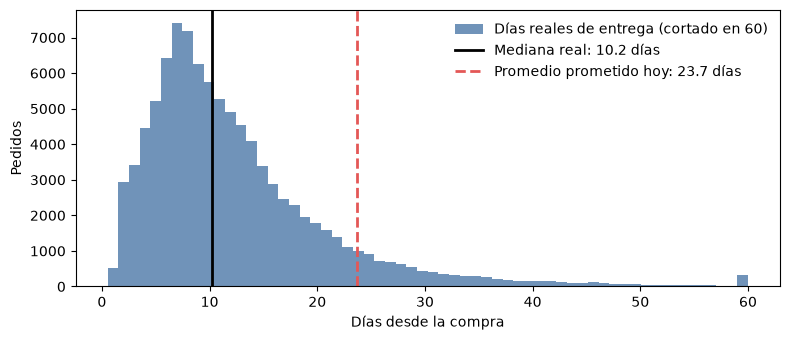

Pedidos que llegan después de la fecha prometida hoy: 6,534 (6.8 %)


In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(real.clip(max=60), bins=60, color="#4C78A8", alpha=0.8, label="Días reales de entrega (cortado en 60)")
ax.axvline(np.median(real), color="black", lw=2, label=f"Mediana real: {np.median(real):.1f} días")
ax.axvline(pedidos["dias_prometidos"].mean(), color="#E45756", lw=2, ls="--",
           label=f"Promedio prometido hoy: {pedidos['dias_prometidos'].mean():.1f} días")
ax.set_xlabel("Días desde la compra"); ax.set_ylabel("Pedidos"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

tarde = (pedidos.order_delivered_customer_date.dt.normalize() > pedidos.order_estimated_delivery_date.dt.normalize())
print(f"Pedidos que llegan después de la fecha prometida hoy: {tarde.sum():,} ({tarde.mean()*100:.1f} %)")

### 3.1 ¿Hay evidencia de que llegar tarde es peor? (reseñas)

No podemos medir cuántas ventas se pierden por prometer plazos largos (no hay datos de visitas ni carritos), pero sí cuánto empeora la **nota de la reseña** cuando un pedido llega después de la fecha prometida. Es correlación, no causa: los pedidos tardíos también pueden ser de regiones lejanas.

In [4]:
reseñas = (pd.read_csv(RAW_DIR / "olist_order_reviews_dataset.csv", usecols=["order_id", "review_score"])
           .groupby("order_id").review_score.mean().rename("nota"))
ev = pedidos.merge(reseñas, left_on="order_id", right_index=True)
ev["dias_vs_prometido"] = (ev.order_delivered_customer_date - ev.order_estimated_delivery_date).dt.total_seconds() / DIA  # > 0: llegó tarde

tramos = [-999, -20, -10, -5, 0, 2, 5, 10, 999]
etiquetas = ["20+ antes", "10-20 antes", "5-10 antes", "0-5 antes", "0-2 tarde", "2-5 tarde", "5-10 tarde", "10+ tarde"]
ev["llegada"] = pd.cut(ev.dias_vs_prometido, tramos, labels=etiquetas)

tabla = ev.groupby("llegada", observed=True).nota.agg(
    nota_media="mean", pedidos="size", pct_reseñas_malas=lambda s: (s <= 2).mean() * 100).round(2)
print(f"Nota media si llega a tiempo o antes: {ev[ev.dias_vs_prometido <= 0].nota.mean():.2f}   |   si llega tarde: {ev[ev.dias_vs_prometido > 0].nota.mean():.2f}")
tabla

Nota media si llega a tiempo o antes: 4.29   |   si llega tarde: 2.57


,nota_media,pedidos,pct_reseñas_malas
llegada,,,
20+ antes,4.29,13409,10.19
10-20 antes,4.33,43496,8.53
5-10 antes,4.28,22442,9.13
0-5 antes,4.15,8816,11.04
0-2 tarde,3.92,2100,15.19
2-5 tarde,2.81,1468,46.19
5-10 tarde,1.89,1861,73.78
10+ tarde,1.70,2232,79.12


**Lo que dice (una frase):** llegar antes no cambia la nota (≈ 4,3 sin importar cuánto antes), pero llegar tarde la hunde, y no de forma lineal: 0–2 días de retraso casi no duele (3,9), de 2 a 5 días la nota cae a 2,8 y pasados 5 días queda en ≈ 1,8. Esto respalda que subestimar es más caro, pero advierte que un costo «por día» simplifica los retrasos largos.

### 3.2 ¿Qué pasa si el 3 a 1 está mal? (sensibilidad)

La proporción 3 a 1 es un supuesto. En lugar de defenderlo como un hecho, se repite el cálculo con otras proporciones. La **mejor constante** es el plazo fijo que minimiza el costo para cada proporción: es el percentil `k/(k+1)` de los tiempos reales.

In [5]:
filas = {}
for k in COST_RATIOS:
    mejor_constante = best_fixed_deadline(real, k)
    fila = {nombre: mean_delivery_cost(real, pred, k) for nombre, pred in estrategias.items()}
    fila["Mejor plazo fijo"] = mean_delivery_cost(real, np.full_like(real, mejor_constante), k)
    fila["Plazo fijo (días)"] = mejor_constante
    fila["% que llegaría tarde"] = (real > mejor_constante).mean() * 100
    filas[f"{k} a 1"] = fila

sensibilidad = pd.DataFrame(filas).T.round(2)
sensibilidad

,Siempre la mediana,Siempre el promedio,Azar según distribución real,Fecha prometida hoy,Mejor plazo fijo,Plazo fijo (días),% que llegaría tarde
1 a 1,6.12,6.41,9.01,12.73,6.12,10.22,50.00
2 a 1,10.36,9.62,13.51,13.50,9.56,13.44,33.33
3 a 1,14.59,12.83,18.02,14.28,12.09,15.72,25.00
5 a 1,23.05,19.24,27.03,15.83,15.81,18.98,16.67
9 a 1,39.98,32.07,45.04,18.93,20.84,23.10,10.00


**Lo que dice (una frase):** la fecha que se promete hoy solo gana al mejor plazo fijo cuando el retraso se castiga entre **5 y 9 veces** más (15,8 vs 15,8 con 5 a 1 y 18,9 vs 20,8 con 9 a 1): la plataforma ya actúa como si el retraso fuera muchísimo más caro que el 3 a 1, así que 3 a 1 es una hipótesis **conservadora**. Y la referencia a vencer es el **mejor plazo fijo** (12,1 con 3 a 1, un plazo de 15,7 días), no la mediana.

**Lo que dice la línea base (una frase):** La fecha que se promete hoy es conservadora (solo el 8 % de los pedidos se subestima) y se equivoca en promedio unos **12,7 días**, el doble que predecir siempre la mediana (**≈ 6,1 días**). Pero como subestimar cuesta 3 veces más, en **costo** la fecha de hoy (**14,3**) queda casi igual que la mediana (**14,6**), y el promedio las supera (**12,8**). El modelo debe ganarle a las tres, no solo a la fecha prometida.

**¿La exactitud (accuracy) sirve como métrica en tu caso? ¿Por qué sí o por qué no?** No aplica: es un problema de regresión, no hay «aciertos» exactos. Se mide cuántos días se equivoca el modelo (MAE) y cuánto cuesta esa equivocación según su dirección.

## 4. Cómo se medirá el éxito

- **Métrica principal: MAE en días** (error absoluto medio). *Aceptada por el grupo.* Por qué es la que importa para el negocio:
  1. **Se lee en el idioma del negocio.** «El modelo se equivoca en promedio X días» lo entiende logística sin formación técnica; el RMSE, el R² o un porcentaje no.
  2. **No deja que unos pocos pedidos raros decidan.** El 1 % de pedidos con peor error aporta solo el **8,5 %** del MAE, pero el **35 %** del RMSE; con el RMSE, 64 pedidos de más de 100 días moverían el resultado casi 5 veces más que con el MAE (6,8 % vs 1,4 %). Lo que le interesa a la empresa es el pedido típico.
  3. **Es coherente con el costo del error.** El MAE es el caso «1 a 1» del mismo costo por día que usamos arriba, así que se pueden comparar en la misma escala (celda de abajo).
  4. **Las alternativas fallan en este caso:** el **MAPE** (error en %) se dispara con entregas muy cortas (537 % de error medio en pedidos de menos de 2 días) y castiga más al sobrestimar; el **R²** no dice cuántos días se falló.
- **Límite del MAE:** trata igual subestimar que sobrestimar, y para el negocio no es lo mismo. Por eso no va solo.
- **Métricas de control:** **costo medio por pedido** con la proporción 3 a 1 (y 2, 5 y 9 a 1); **RMSE** (para vigilar errores grandes).
- **Alcance del modelo:** es una **regresión lineal** cuyo objetivo es predecir los **días de entrega**. Como apartado secundario se ofrecerá la **probabilidad de retraso** (pedido que llega después de la fecha prometida), derivada de esa predicción; los retrasos no son lo que se entrena. Se evaluará con ROC-AUC (¿separa los tardíos de los puntuales?), Brier score y calibración (¿el «30 % de riesgo» se cumple 3 de cada 10 veces?). Hay pocos retrasos (6,8 %), así que esta parte es complementaria.
- **Qué resultado haría que el negocio diga «sirve»:** un costo medio por pedido menor que el del **mejor plazo fijo** de la tabla 3.2 (**12,1** con 3 a 1) y un MAE claramente menor que **6,1 días**, en datos que el modelo no vio. Para que la conclusión sea sólida, debe ganar también con 2, 5 y 9 a 1. *Umbral exacto por acordar con el instructor.*

In [6]:
# ¿Cómo se comportan las métricas candidatas? (con la regla «siempre la mediana», que es un modelo trivial)
e = real - np.median(real)
mae, rmse = np.abs(e).mean(), np.sqrt((e ** 2).mean())

# 1) ¿Quién manda en cada métrica? Porción del error total que aporta el 1 % de pedidos peor predichos
k = int(len(e) * 0.01)
peso_mae  = np.sort(np.abs(e))[::-1][:k].sum() / np.abs(e).sum() * 100
peso_rmse = np.sort(e ** 2)[::-1][:k].sum() / (e ** 2).sum() * 100

# 2) ¿Cuánto cambia cada métrica si se quitan los pedidos de más de 100 días (decisión 2 del EDA)?
ok = real <= 100
cambio_mae  = (np.abs(e[ok]).mean() / mae - 1) * 100
cambio_rmse = (np.sqrt((e[ok] ** 2).mean()) / rmse - 1) * 100

# 3) MAPE en entregas cortas
corto = real < 2
mape_corto = (np.abs(e[corto]) / real[corto]).mean() * 100

# 4) MAE = costo con proporción 1 a 1
assert abs(mean_delivery_cost(real, np.full_like(real, np.median(real)), 1) - mae) < 1e-9

comparacion = pd.DataFrame({
    "MAE": [mae, peso_mae, cambio_mae],
    "RMSE": [rmse, peso_rmse, cambio_rmse],
}, index=["valor (días) con la mediana", "% del error que aporta el 1 % peor", "cambio (%) al quitar los de más de 100 días"]).round(1)
display(comparacion)
print(f"MAPE en pedidos de menos de 2 días ({corto.sum():,} pedidos): {mape_corto:.0f} %  -> inestable")

,MAE,RMSE
valor (días) con la mediana,6.1,9.8
% del error que aporta el 1 % peor,8.5,35.1
cambio (%) al quitar los de más de 100 días,-1.4,-6.8


MAPE en pedidos de menos de 2 días (1,585 pedidos): 537 %  -> inestable


## 4.1 Para explicarlo en el grupo (palabras simples)

> Este bloque existe para que **cualquier integrante**, aunque no haya escrito el notebook, pueda explicar el caso en 1 minuto.

**La idea en tres frases.** (1) Queremos decirle al cliente cuántos días tardará su pedido. (2) Si decimos menos días de los reales, el pedido llega tarde y el cliente se enoja; si decimos más, llega antes de lo dicho y casi nadie se queja, pero la tienda parece lenta. (3) Por eso un error «por debajo» cuesta más que uno «por encima»: usamos **3 veces más** como punto de partida y comprobamos que la conclusión resiste con 2, 5 y 9.

**Un ejemplo con un pedido que tarda 10 días:**

| Si el modelo dice… | Qué pasa | Días de error | Costo (3 a 1) |
|---|---|---|---|
| 7 días | Llega 3 días después de lo dicho (retraso) | 3 | 3 × 3 = **9** |
| 13 días | Llega 3 días antes de lo dicho | 3 | 1 × 3 = **3** |

El error en días es el mismo, pero el primero cuesta el triple.

**Por qué creemos que es así (evidencia de los datos):** cuando el pedido llega tarde, la nota de la reseña baja de 4,3 a 2,6; cuando llega antes, no cambia. Y la plataforma ya promete plazos muy largos (23,7 días en promedio vs 10,2 reales), como si el retraso costara entre 5 y 9 veces más.

**Qué no sabemos:** cuántas ventas se pierden por prometer plazos largos. No hay datos de eso, por eso el 3 a 1 es un supuesto y lo probamos con otros valores.

**Preguntas para comprobar que se entendió:**
1. *¿Por qué no usamos el porcentaje de aciertos?* Porque es un número continuo (días): nunca se «acierta» exacto; medimos cuántos días nos equivocamos.
2. *¿Por qué MAE y no RMSE?* Porque el RMSE lo dominan unos pocos pedidos raros (el 1 % peor aporta el 35 % del RMSE y solo el 8,5 % del MAE).
3. *¿Por qué el MAE no basta?* Porque no distingue entre llegar tarde y llegar antes; por eso añadimos el costo con la proporción 3 a 1.
4. *¿Y si el 3 a 1 estuviera mal?* Se repite con 2, 5 y 9 a 1; si el modelo gana en todos, la conclusión no depende del supuesto.
5. *¿Cuál es la referencia a vencer?* Un plazo fijo de unos 15,7 días para todos los pedidos (costo 12,1 con 3 a 1).

## 5. Lo que podría salir mal

- **Fuga de información (¿qué columna se conoce solo después de la decisión?):** `order_delivered_carrier_date`, `order_delivered_customer_date`, `order_status` y todas las `review_*`. La decisión se toma al comprar; esas columnas no existen todavía. `order_approved_at` se medirá con y sin ella.
- **Sesgos o equidad (¿a quién podría perjudicar el modelo?):** a clientes de regiones remotas con pocos pedidos (por ejemplo, AM o RR, con 25 días de mediana frente a 7 de SP). El error se revisará **por estado**.
- **Datos personales o confidenciales:** los identificadores vienen anonimizados; no se usan los comentarios de reseñas ni ids como variables.
- **Hasta dónde puede decidir el modelo y dónde debe decidir una persona:** el modelo estima plazos y marca riesgo de retraso; no decide compensaciones ni cancelaciones. Los datos son de 2016–2018 de una sola plataforma y no incluyen clima, huelgas ni feriados.

## 6. Cierre

- [x] Pregunta, quién decide y costos escritos **con números** (la proporción 3 a 1 está marcada como propuesta).
- [x] Línea base calculada, con evidencia de reseñas y sensibilidad (1, 2, 3, 5 y 9 a 1).
- [x] Métrica principal elegida y justificada (MAE, aceptada por el grupo; sección 4).
- [x] Resumen copiado a `reports/00_caso.md` (métrica, costo 3 a 1 y criterio de éxito coinciden con este notebook).
- [x] Alguien que **no** escribió este notebook sabe explicar por qué un error cuesta más que el otro (guía y preguntas de comprobación en 4.1; el grupo debe repasarlas en voz alta).